# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear old gradients
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

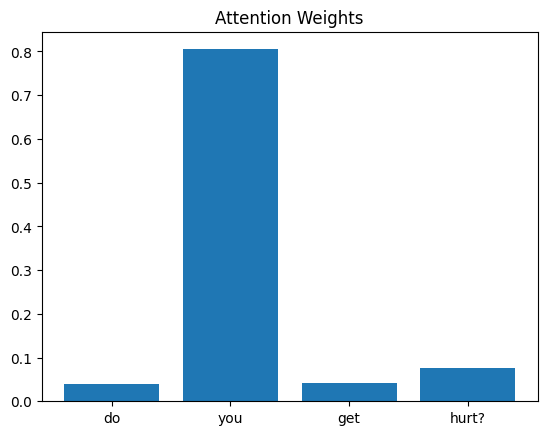

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

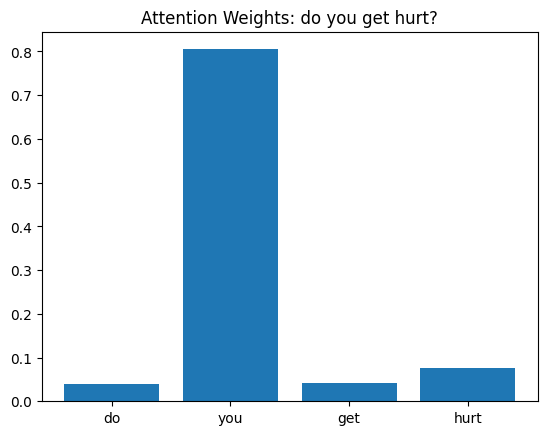

Highest attention word: you
Predicted answer: I don't have a body.


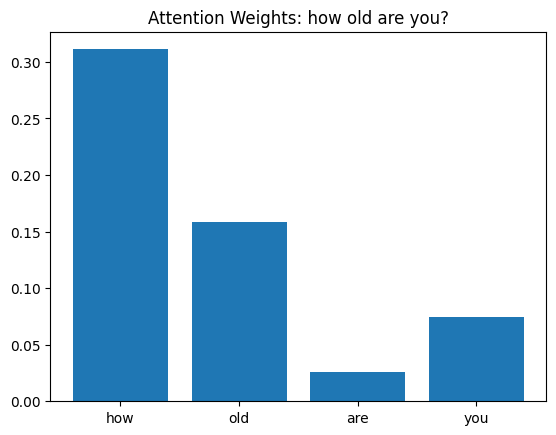

Highest attention word: how
Predicted answer: Age doesn't really apply to me.


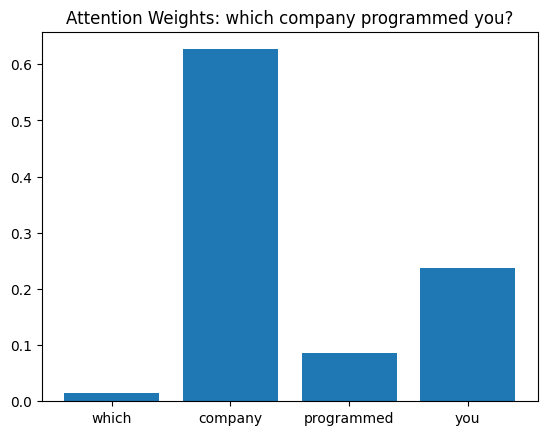

Highest attention word: company
Predicted answer: People created me.


In [7]:
def show_attention(i):
    # words exactly as the tokenizer sees them (padding removed)
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t != 0]
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()

    plt.bar(words, w)
    plt.title(f"Attention Weights: {df['question'][i]}")
    plt.show()
    print("Highest attention word:", words[w.index(max(w))])
    print("Predicted answer:", df[df["answer_id"] == prediction.argmax().item()]["answer"].iloc[0])

for i in [0, 24, 44]:
    show_attention(i)

**Answer:** Mostly yes.
- *"do you get hurt?"* → highest weight on **you**. The model only needs to know the question is about the bot itself, so "you" is a reasonable focus, although "hurt" carries more meaning.
- *"how old are you?"* → highest weight on **how**. In this dataset "how" appears mostly in age questions ("how old", "how long"), so it is a useful clue, but "old" would be the more meaningful word for a human.
- *"which company programmed you?"* → highest weight on **company**, which is clearly the key word for the "People created me" answer.

All three questions got the correct answer. The model focuses on words that help it **separate the answer groups** in this small dataset, which are often, but not always, the words a person would think are most important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

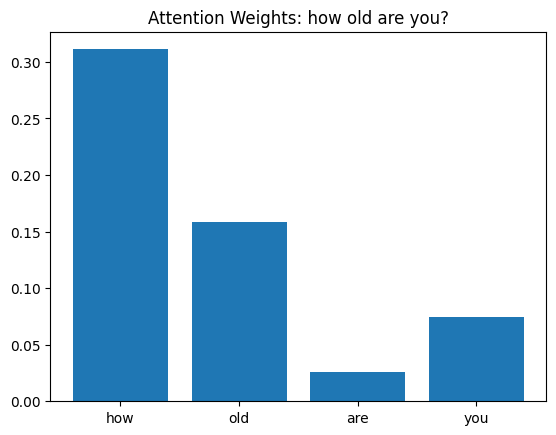

Highest attention word: how
Predicted answer: Age doesn't really apply to me.


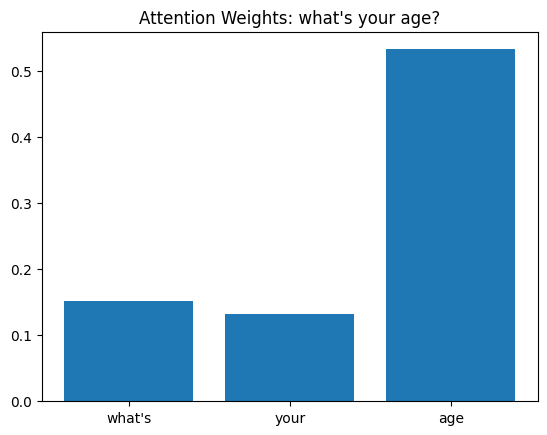

Highest attention word: age
Predicted answer: Age doesn't really apply to me.


In [8]:
# Two questions with the same meaning but different wording
q1 = df.index[df["question"] == "how old are you?"][0]
q2 = df.index[df["question"] == "what's your age?"][0]

for i in [q1, q2]:
    show_attention(i)

**Answer:** *"how old are you?"* and *"what's your age?"* mean the same thing, and both get the correct answer ("Age doesn't really apply to me."), but the model focuses on **different words**: **how** in the first and **age** in the second.

This shows that attention does not look for a fixed word. For each sentence it picks whichever word is most useful for the prediction in that context. Different wording leads to different focus words, but they all point to the same meaning, so the model still reaches the same answer.